# 05.5 · Support vector machines *(optional)*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/05-svm/lesson.ipynb)

Read the [README](README.md) first. This notebook:

1. Draws the widest-margin line on 40 points and finds the support vectors.
2. Shows what `C` does to the margin.
3. Bends the boundary with the RBF kernel and shows what `gamma` does.
4. Shows why SVMs need scaling, and how they compare on churn.
5. Times SVMs as data grows, which explains why they are less popular today.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import make_blobs, make_moons
from sklearn.svm import SVC, SVR

X_blob, y_blob = make_blobs(n_samples=40, centers=2, random_state=6)

def plot_svm(model, X, y, ax, title):
    """Scatter the points, shade the decision function, draw boundary, margins and support vectors."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=25, edgecolors="k")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolors="none", edgecolors="k", linewidths=1.5)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

## 1. The widest corridor

weights w = [-0.254 -0.838], intercept b = -3.211
margin width = 2 / ||w|| = 2 / 0.876 = 2.28
support vectors: 3 of 40 points


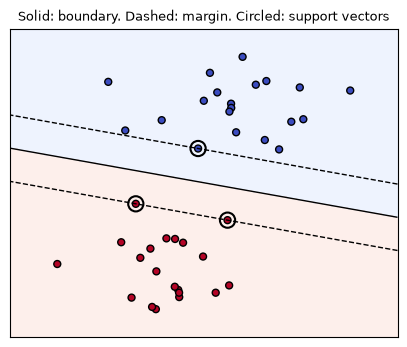

In [2]:
svm = SVC(kernel="linear", C=1).fit(X_blob, y_blob)
w = svm.coef_[0]
print(f"weights w = {w.round(3)}, intercept b = {svm.intercept_[0]:.3f}")
print(f"margin width = 2 / ||w|| = 2 / {np.linalg.norm(w):.3f} = {2 / np.linalg.norm(w):.2f}")
print(f"support vectors: {svm.n_support_.sum()} of {len(X_blob)} points")

fig, ax = plt.subplots(figsize=(5, 4))
plot_svm(svm, X_blob, y_blob, ax, "Solid: boundary. Dashed: margin. Circled: support vectors")
plt.show()

Only the circled points touch the edges of the corridor. Delete any other point and the boundary does not move. That is why they are called **support** vectors: they hold the boundary up.

## 2. `C`: how much do mistakes cost?

C =   0.01: margin width 5.71, support vectors 18
C =      1: margin width 2.28, support vectors 3
C =    100: margin width 2.28, support vectors 3


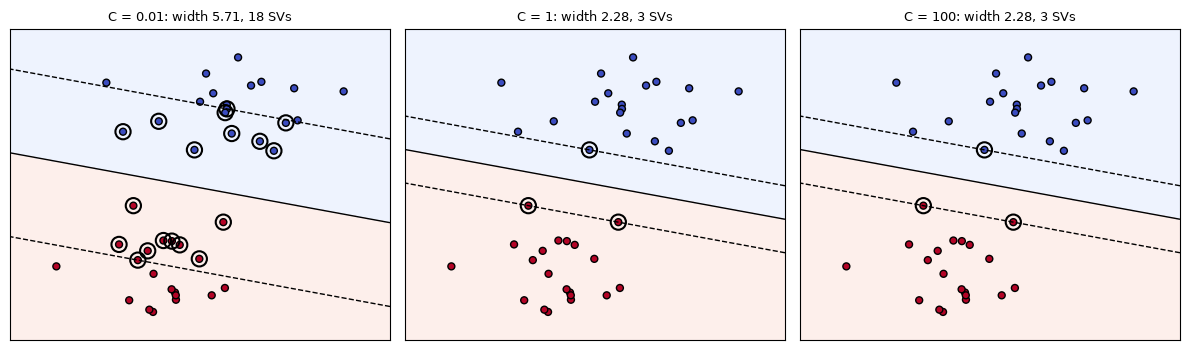

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, C in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=C).fit(X_blob, y_blob)
    width = 2 / np.linalg.norm(m.coef_[0])
    print(f"C = {C:>6}: margin width {width:.2f}, support vectors {m.n_support_.sum()}")
    plot_svm(m, X_blob, y_blob, ax, f"C = {C}: width {width:.2f}, {m.n_support_.sum()} SVs")
plt.tight_layout(); plt.show()

Small `C` = mistakes are cheap, so the SVM chooses a **wide** corridor and lets many points sit inside it (many support vectors). Large `C` = mistakes are expensive, so the corridor narrows until it is defined by the few closest points. These two blobs are cleanly separable, so `C = 1` and `C = 100` give the same answer.

## 3. Curved boundaries: the RBF kernel

Two interleaved half-moons: no straight line separates them.

linear, gamma=scale: train acc 0.833, CV acc 0.837, SVs 110
   rbf, gamma=  0.1: train acc 0.840, CV acc 0.837, SVs 127


   rbf, gamma=    1: train acc 0.957, CV acc 0.957, SVs 73


   rbf, gamma=   10: train acc 0.970, CV acc 0.960, SVs 110
   rbf, gamma=  100: train acc 0.983, CV acc 0.927, SVs 257


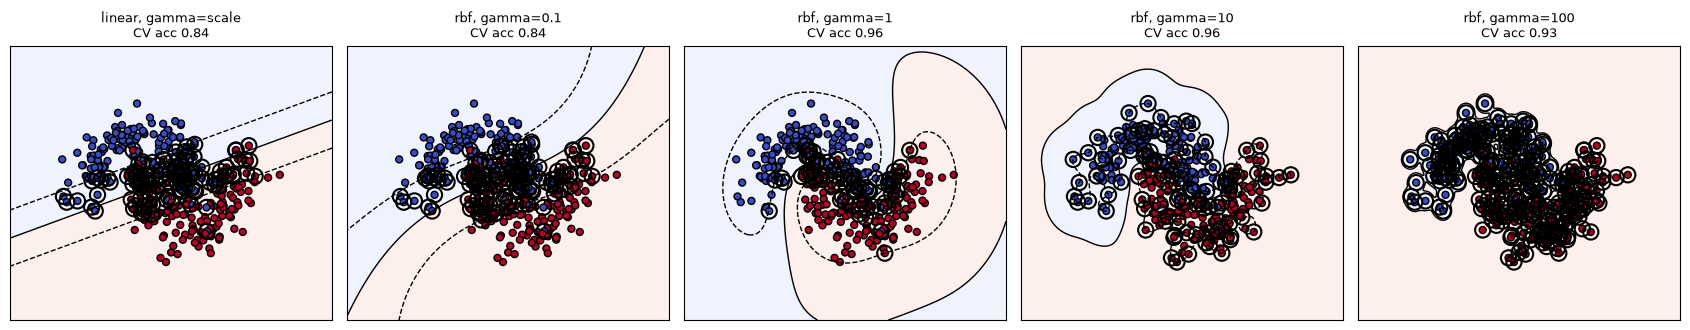

In [4]:
from sklearn.model_selection import cross_val_score
X_moon, y_moon = make_moons(n_samples=300, noise=0.25, random_state=0)

settings = [("linear", "scale"), ("rbf", 0.1), ("rbf", 1), ("rbf", 10), ("rbf", 100)]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (kernel, gamma) in zip(axes, settings):
    m = SVC(kernel=kernel, gamma=gamma, C=1)
    cv_acc = cross_val_score(m, X_moon, y_moon, cv=5).mean()
    m.fit(X_moon, y_moon)
    print(f"{kernel:>6}, gamma={gamma!s:>5}: train acc {m.score(X_moon, y_moon):.3f}, CV acc {cv_acc:.3f}, SVs {m.n_support_.sum()}")
    plot_svm(m, X_moon, y_moon, ax, f"{kernel}, gamma={gamma}\nCV acc {cv_acc:.2f}")
plt.tight_layout(); plt.show()

- **Linear**: the best straight line; it cannot follow the moons.
- **RBF, small gamma**: each point's influence reaches far, so the boundary is almost straight.
- **RBF, gamma 1–10**: the boundary bends around the moons. Best cross-validated accuracy.
- **RBF, gamma 100**: each point influences only its tiny neighbourhood. The boundary wraps around individual points: training accuracy rises, CV accuracy falls. Overfitting, again.

## 4. Scaling matters

The RBF kernel measures **distance**, so a feature measured in pounds (spend up to tens of thousands) drowns one measured in orders (1 to 100). Exactly the KNN problem from 03.2.

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


In [7]:
unscaled = SVC(kernel="rbf", probability=True, random_state=42)
scaled = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42))
print(f"SVM, unscaled: CV AUC {cv_auc(unscaled):.3f}")
print(f"SVM, scaled:   CV AUC {cv_auc(scaled):.3f}, test AUC {test_auc(scaled):.3f}")

SVM, unscaled: CV AUC 0.718


SVM, scaled:   CV AUC 0.731, test AUC 0.719


Without scaling, the SVM is noticeably worse. (scikit-learn's default `gamma="scale"` softens the damage by adapting to the overall spread of the data, but it cannot fix features on wildly different scales.) With scaling it is a respectable model, but it does not beat the logistic benchmark on this table.

## 5. SVR: the regression version

Same idea for numbers: fit a tube of half-width $\varepsilon$ around the data and ignore errors inside it; only points outside the tube pull on the line. On the five customers from 02.2, with $\varepsilon = 5$:

In [8]:
five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
svr = SVR(kernel="linear", C=100, epsilon=5).fit(five[["visits_last_month"]], five["spend_next_month"])
print(f"SVR line: spend = {svr.coef_[0][0]:.2f} × visits + {svr.intercept_[0]:.2f}  (least squares: 12.5 × visits + 25)")
print(f"prediction for 7 visits: £{svr.predict(pd.DataFrame({'visits_last_month': [7]}))[0]:.2f}")

SVR line: spend = 12.50 × visits + 25.00  (least squares: 12.5 × visits + 25)
prediction for 7 visits: £112.50


On these five points the SVR lands on exactly the least-squares line from 02.2. That will not happen in general: SVR ignores small errors and is less pulled by outliers, so on messier data the two lines differ.

## 6. Why SVMs are less common today

Training a kernel SVM compares many pairs of rows, so its cost grows roughly with the **square** of the number of rows (or worse). Tree ensembles grow roughly linearly. Time both on growing slices of a synthetic table.

In [9]:
import time
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

Xbig, ybig = make_classification(n_samples=16_000, n_features=10, random_state=0)
for n in [2_000, 4_000, 8_000, 16_000]:
    t0 = time.time(); make_pipeline(StandardScaler(), SVC()).fit(Xbig[:n], ybig[:n]); t_svm = time.time() - t0
    t0 = time.time(); RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=0).fit(Xbig[:n], ybig[:n]); t_rf = time.time() - t0
    print(f"{n:>6} rows: SVM {t_svm:5.2f} s   random forest {t_rf:5.2f} s")

  2000 rows: SVM  0.01 s   random forest  0.08 s


  4000 rows: SVM  0.03 s   random forest  0.11 s


  8000 rows: SVM  0.10 s   random forest  0.23 s


 16000 rows: SVM  0.36 s   random forest  0.59 s


On small data the SVM is actually *faster*. But look at the growth: each doubling of the rows multiplies the SVM's time by roughly 3–4, the forest's by only about 2. Exact seconds depend on your machine, but the growth rates do not: somewhere in the thousands to tens of thousands of rows the SVM falls behind, and from there the gap widens with every doubling. At a million rows, a kernel SVM becomes impractical. Add the need for scaling, no native missing values, no probabilities without extra work (`probability=True` runs an internal cross-validation), and you see why tree ensembles took over tabular data. SVMs remain excellent for **small, high-dimensional** problems (text with thousands of word features, some bioinformatics), and the margin idea lives on inside many other methods.

## Quiz answers

1. The points closest to the boundary, lying on or inside the margin. Only they determine where the boundary is.
2. Small `C`: a wide margin that tolerates misclassified points (more regularised). Large `C`: a narrow margin that tries to classify every training point correctly (risk of overfitting).
3. The RBF kernel lets the SVM draw curved boundaries by measuring similarity as distance; `gamma` sets how far each point's influence reaches. Large `gamma` = very local = wiggly boundary that can overfit.
4. The RBF kernel (and the margin) are based on distances, so features with large numeric ranges dominate unless all features are scaled.
5. Training time grows much faster than linearly with the number of rows, they need scaling, they lack native missing-value handling and calibrated probabilities, and tree ensembles are usually at least as accurate on tabular data.

**Next:** [05.6 Hyperparameter tuning](../06-hyperparameter-tuning/)